# CycleTwin AI - PCOS analysis (single source of truth)
Run order: **Kernel > Restart & Run All**. Reads `run_final/` only. Never re-runs the TVAE generator.
Writes tables (CSV), figures (300-dpi PNG) and `results_summary.json` into `results/`, and the app model into `../models/`.

Sections: 1 Setup | 2 Data and leak guards | 3 EDA | 4 Model training and test | 5 Extra evaluation (2b) | 6 Save app model | 7 SHAP | 8 Export

## 1. Setup

In [2]:
import os
os.environ['LOKY_MAX_CPU_COUNT'] = str(os.cpu_count() or 4)   # silences the Windows 'wmic' warning
import warnings
warnings.filterwarnings('ignore')

import json, pickle, hashlib, platform, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy, sklearn, xgboost

from scipy.stats import pointbiserialr, mannwhitneyu, chi2_contingency
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, cross_validate, cross_val_predict
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, roc_curve,
                             accuracy_score, recall_score, precision_score, f1_score,
                             average_precision_score, brier_score_loss)
from xgboost import XGBClassifier

sns.set_style('whitegrid')
pd.set_option('display.max_columns', 100)
%matplotlib inline

TARGET = 'PCOS (Y/N)'
SEED = 42
RESULTS = 'results'
os.makedirs(RESULTS, exist_ok=True)

def save_fig(name):
    plt.savefig(f'{RESULTS}/{name}.png', dpi=300, bbox_inches='tight')

def save_table(d, name, index=True):
    d.to_csv(f'{RESULTS}/{name}.csv', index=index)


## 2. Data, leak guards and cleaning

In [3]:
IMPOSSIBLE = {
    'Pulse rate(bpm)': (40, 200),
    'BP _Systolic (mmHg)': (70, 250),
    'BP _Diastolic (mmHg)': (40, 150),
    'FSH(mIU/mL)': (0, 100),
    'LH(mIU/mL)': (0, 100),
    'Vit D3 (ng/mL)': (0, 200),
}

train_real = pd.read_csv('run_final/train_real.csv')
test_real  = pd.read_csv('run_final/test_real.csv')
aug_train  = pd.read_csv('run_final/augmented_train.csv')
for d in (train_real, test_real, aug_train):
    d.columns = d.columns.str.strip()

# leak guards (raw values, before cleaning)
rk = lambda d: set(d[list(train_real.columns)].round(4).fillna(-999).astype(str).agg('|'.join, axis=1))
assert not (rk(test_real) & rk(train_real)), 'train/test overlap'
assert not (rk(test_real) & rk(aug_train)), 'TEST ROW INSIDE AUGMENTED TRAIN'
for d in (train_real, test_real, aug_train):
    assert set(d['Cycle(R/I)'].unique()) <= {0, 1}, 'cycle not 0/1'
print('leak guards passed')
print('train_real', train_real.shape, '| test_real', test_real.shape, '| aug_train', aug_train.shape)

print('duplicates (real train):', train_real.duplicated().sum())
print('nulls (real train):', int(train_real.isnull().sum().sum()))
bad = {c: int(((train_real[c] < lo) | (train_real[c] > hi)).sum()) for c, (lo, hi) in IMPOSSIBLE.items()}
print('impossible values in real train:', bad)

def clean(d):
    d = d.copy()
    for c, (lo, hi) in IMPOSSIBLE.items():
        d.loc[(d[c] < lo) | (d[c] > hi), c] = np.nan
    d['BMI'] = d['Weight (Kg)'] / (d['Height(Cm)'] / 100) ** 2
    d['Waist:Hip Ratio'] = d['Waist(inch)'] / d['Hip(inch)']
    d['FSH/LH'] = (d['FSH(mIU/mL)'] / d['LH(mIU/mL)']).replace([np.inf, -np.inf], np.nan)
    return d

train_real, test_real, aug_train = clean(train_real), clean(test_real), clean(aug_train)
real_all = pd.concat([train_real, test_real], ignore_index=True)     # 541 real records (Table 1 only)
assert len(real_all) == 541
cols = [c for c in train_real.columns if c != TARGET]
print('features:', len(cols))


leak guards passed
train_real (432, 42) | test_real (109, 42) | aug_train (1932, 42)
duplicates (real train): 0
nulls (real train): 0
impossible values in real train: {'Pulse rate(bpm)': 2, 'BP _Systolic (mmHg)': 1, 'BP _Diastolic (mmHg)': 1, 'FSH(mIU/mL)': 1, 'LH(mIU/mL)': 0, 'Vit D3 (ng/mL)': 2}
features: 41


## 3. Exploratory data analysis
Table 1 uses all 541 real records. Every feature-related analysis below uses **real train only** (432 records).

In [4]:
categorical_cols = ['Blood Group', 'Cycle(R/I)', 'Pregnant(Y/N)', 'Weight gain(Y/N)', 'hair growth(Y/N)',
                    'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)']
continuous_cols = [c for c in cols if c not in categorical_cols]
print(len(continuous_cols), 'continuous |', len(categorical_cols), 'categorical')

# ---- Table 1 (all 541 real records)
g0, g1 = real_all[real_all[TARGET] == 0], real_all[real_all[TARGET] == 1]
fmt = lambda s: f'{s.median():.2f} [{s.quantile(.25):.2f}-{s.quantile(.75):.2f}]'
rows = [{'variable': 'N', 'overall': len(real_all), 'no_pcos': len(g0), 'pcos': len(g1), 'p_value': np.nan, 'missing': 0}]
for c in continuous_cols:
    p = mannwhitneyu(g0[c].dropna(), g1[c].dropna()).pvalue
    rows.append({'variable': c + ' - median [IQR]', 'overall': fmt(real_all[c]), 'no_pcos': fmt(g0[c]),
                 'pcos': fmt(g1[c]), 'p_value': p, 'missing': int(real_all[c].isna().sum())})
for c in categorical_cols:
    p = chi2_contingency(pd.crosstab(real_all[c], real_all[TARGET]))[1]
    levels = sorted(real_all[c].dropna().unique()) if c == 'Blood Group' else [1]
    for i, lv in enumerate(levels):
        n = lambda d: f'{int((d[c] == lv).sum())} ({100 * (d[c] == lv).mean():.1f}%)'
        rows.append({'variable': f'{c} = {int(lv)}', 'overall': n(real_all), 'no_pcos': n(g0), 'pcos': n(g1),
                     'p_value': p if i == 0 else np.nan, 'missing': int(real_all[c].isna().sum()) if i == 0 else ''})
table1 = pd.DataFrame(rows)
save_table(table1, 'table1_descriptive', index=False)
table1.round(4)


31 continuous | 10 categorical


,variable,overall,no_pcos,pcos,p_value,missing
0,N,541,364,177,NaN,0
1,Age (yrs) - median [IQR],31.00 [28.00-35.00],32.00 [28.00-36.00],29.00 [27.00-33.00],0.0000,0
2,Weight (Kg) - median [IQR],59.00 [52.00-65.00],58.00 [52.00-64.00],62.00 [55.00-70.00],0.0000,0
3,Height(Cm) - median [IQR],156.00 [152.00-160.00],156.00 [152.00-160.00],158.00 [152.00-161.00],0.1602,0
4,BMI - median [IQR],24.24 [21.71-26.64],23.62 [21.37-26.09],25.15 [23.01-28.26],0.0000,0
5,Pulse rate(bpm) - median [IQR],72.00 [72.00-74.00],72.00 [72.00-74.00],72.00 [72.00-74.00],0.0058,2
6,RR (breaths/min) - median [IQR],18.00 [18.00-20.00],18.00 [18.00-20.00],20.00 [18.00-20.00],0.2809,0
7,Hb(g/dl) - median [IQR],11.00 [10.50-11.70],11.00 [10.50-11.53],11.00 [10.70-11.90],0.0247,0
8,Cycle length(days) - median [IQR],5.00 [4.00-5.00],5.00 [5.00-6.00],5.00 [3.00-5.00],0.0000,0
9,Marraige Status (Yrs) - median [IQR],7.00 [4.00-10.00],7.00 [4.00-11.00],6.00 [3.00-10.00],0.0035,0


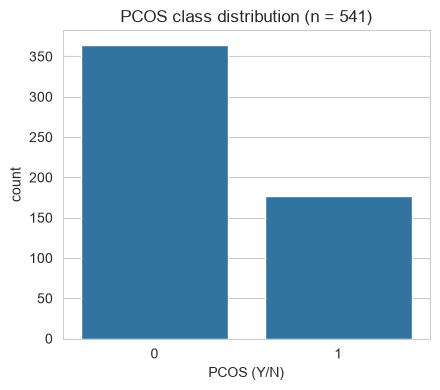

{0: 0.673, 1: 0.327}


In [5]:
plt.figure(figsize=(4.5, 4))
sns.countplot(x=TARGET, data=real_all)
plt.title('PCOS class distribution (n = 541)')
plt.tight_layout(); save_fig('fig_class_distribution'); plt.show()
print(real_all[TARGET].value_counts(normalize=True).round(3).to_dict())


In [6]:
hcg = [c for c in real_all.columns if 'beta-HCG' in c]
print({c: int((real_all[c] == 1.99).sum()) for c in hcg}, 'records equal to 1.99, of', len(real_all))

{'I   beta-HCG(mIU/mL)': 191, 'II    beta-HCG(mIU/mL)': 308} records equal to 1.99, of 541


In [7]:
df = train_real.copy()                                   # real train only from here on
num_imp = SimpleImputer(strategy='median').fit(df[cols])
df_stat = pd.DataFrame(num_imp.transform(df[cols]), columns=cols, index=df.index)
df_stat[TARGET] = df[TARGET].values

q1, q3 = df[continuous_cols].quantile(0.25), df[continuous_cols].quantile(0.75)
iqr = q3 - q1
outlier_count = ((df[continuous_cols] < (q1 - 1.5 * iqr)) | (df[continuous_cols] > (q3 + 1.5 * iqr))).sum()
outliers = outlier_count.sort_values(ascending=False).head(10).rename('n_outliers (IQR rule)')
save_table(outliers.to_frame(), 'table_outliers_train')
outliers


No. of aborptions         83
II    beta-HCG(mIU/mL)    72
Pulse rate(bpm)           71
Cycle length(days)        63
AMH(ng/mL)                41
I   beta-HCG(mIU/mL)      36
FSH/LH                    33
PRG(ng/mL)                32
RBS(mg/dl)                23
TSH (mIU/L)               21
Name: n_outliers (IQR rule), dtype: int64

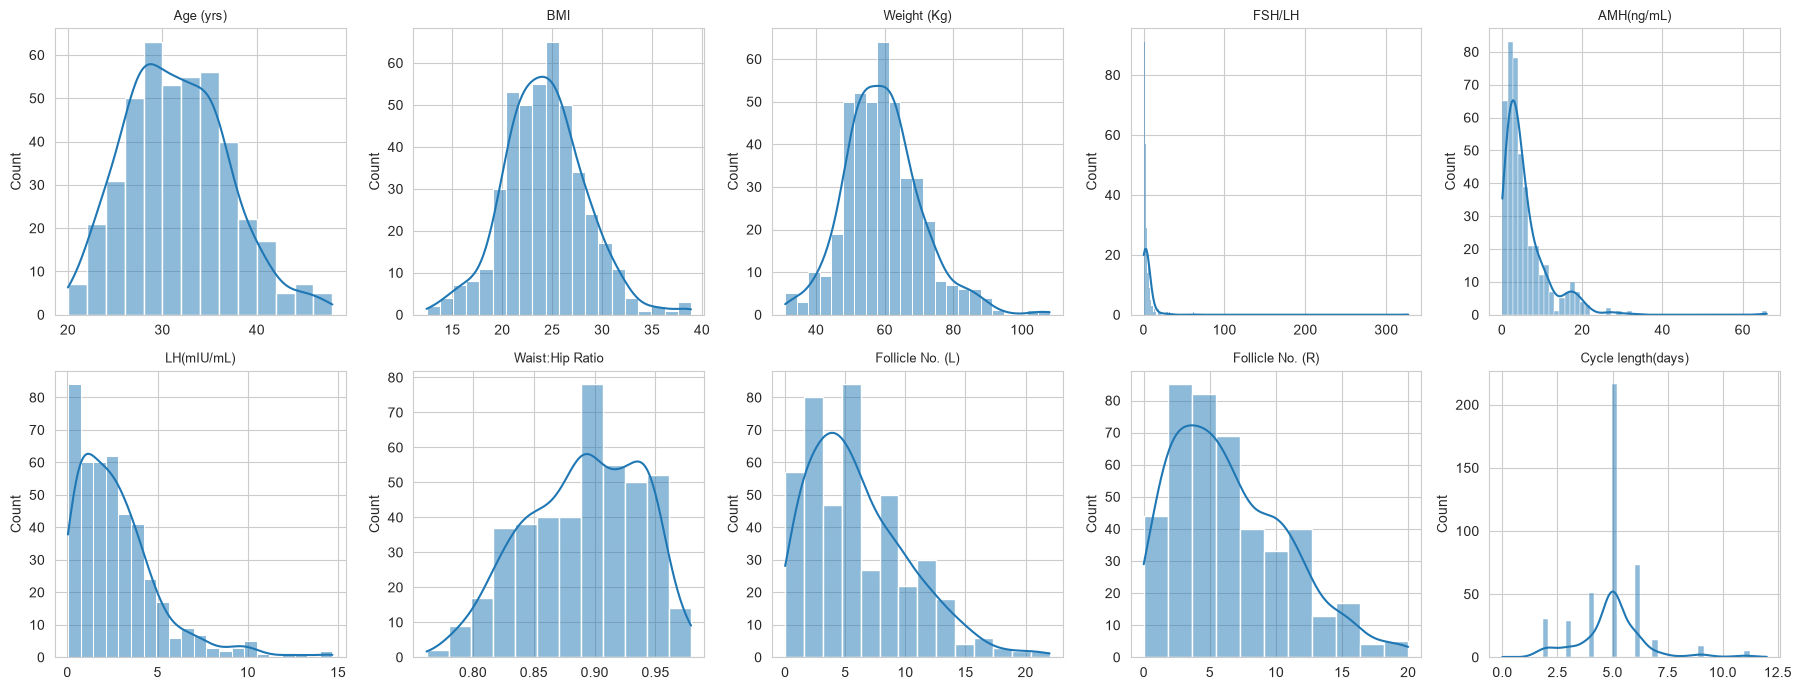

In [8]:
key_numeric = ['Age (yrs)', 'BMI', 'Weight (Kg)', 'FSH/LH', 'AMH(ng/mL)', 'LH(mIU/mL)',
               'Waist:Hip Ratio', 'Follicle No. (L)', 'Follicle No. (R)', 'Cycle length(days)']
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, c in zip(axes.flatten(), key_numeric):
    sns.histplot(df[c], kde=True, ax=ax); ax.set_title(c, fontsize=9); ax.set_xlabel('')
plt.tight_layout(); save_fig('fig_distributions_key_numeric'); plt.show()


In [9]:
# numeric features vs target (real train). BH = Benjamini-Hochberg multiple-testing correction
rows = []
for c in continuous_cols:
    a, b = df_stat.loc[df_stat[TARGET] == 0, c], df_stat.loc[df_stat[TARGET] == 1, c]
    r, p = pointbiserialr(df_stat[TARGET], df_stat[c])
    rows.append([c, r, p, mannwhitneyu(a, b).pvalue, a.mean(), b.mean()])
num_vs_target = pd.DataFrame(rows, columns=['feature', 'point_biserial_r', 'p_value', 'p_mannwhitney',
                                            'mean_no_pcos', 'mean_pcos'])
num_vs_target['p_mannwhitney_BH'] = multipletests(num_vs_target['p_mannwhitney'], method='fdr_bh')[1]
num_vs_target['abs_r'] = num_vs_target['point_biserial_r'].abs()
num_vs_target = num_vs_target.sort_values('abs_r', ascending=False).reset_index(drop=True)
save_table(num_vs_target, 'table_numeric_vs_target', index=False)
num_vs_target.round(4)


,feature,point_biserial_r,p_value,p_mannwhitney,mean_no_pcos,mean_pcos,p_mannwhitney_BH,abs_r
0,Follicle No. (R),0.6494,0.0000,0.0000,4.5430,10.5816,0.0000,0.6494
1,Follicle No. (L),0.6177,0.0000,0.0000,4.2646,9.8014,0.0000,0.6177
2,AMH(ng/mL),0.2926,0.0000,0.0000,4.5116,8.2465,0.0000,0.2926
3,Weight (Kg),0.2332,0.0000,0.0000,57.6027,63.1525,0.0000,0.2332
4,Waist(inch),0.2148,0.0000,0.0000,33.2543,34.9007,0.0000,0.2148
5,BMI,0.2143,0.0000,0.0000,23.6499,25.5186,0.0000,0.2143
6,Hip(inch),0.2001,0.0000,0.0001,37.4433,39.1348,0.0002,0.2001
7,Cycle length(days),-0.1934,0.0001,0.0000,5.1615,4.5319,0.0000,0.1934
8,Age (yrs),-0.1608,0.0008,0.0001,32.0241,30.1631,0.0004,0.1608
9,Avg. F size (L) (mm),0.1607,0.0008,0.0028,14.5491,15.8156,0.0072,0.1607


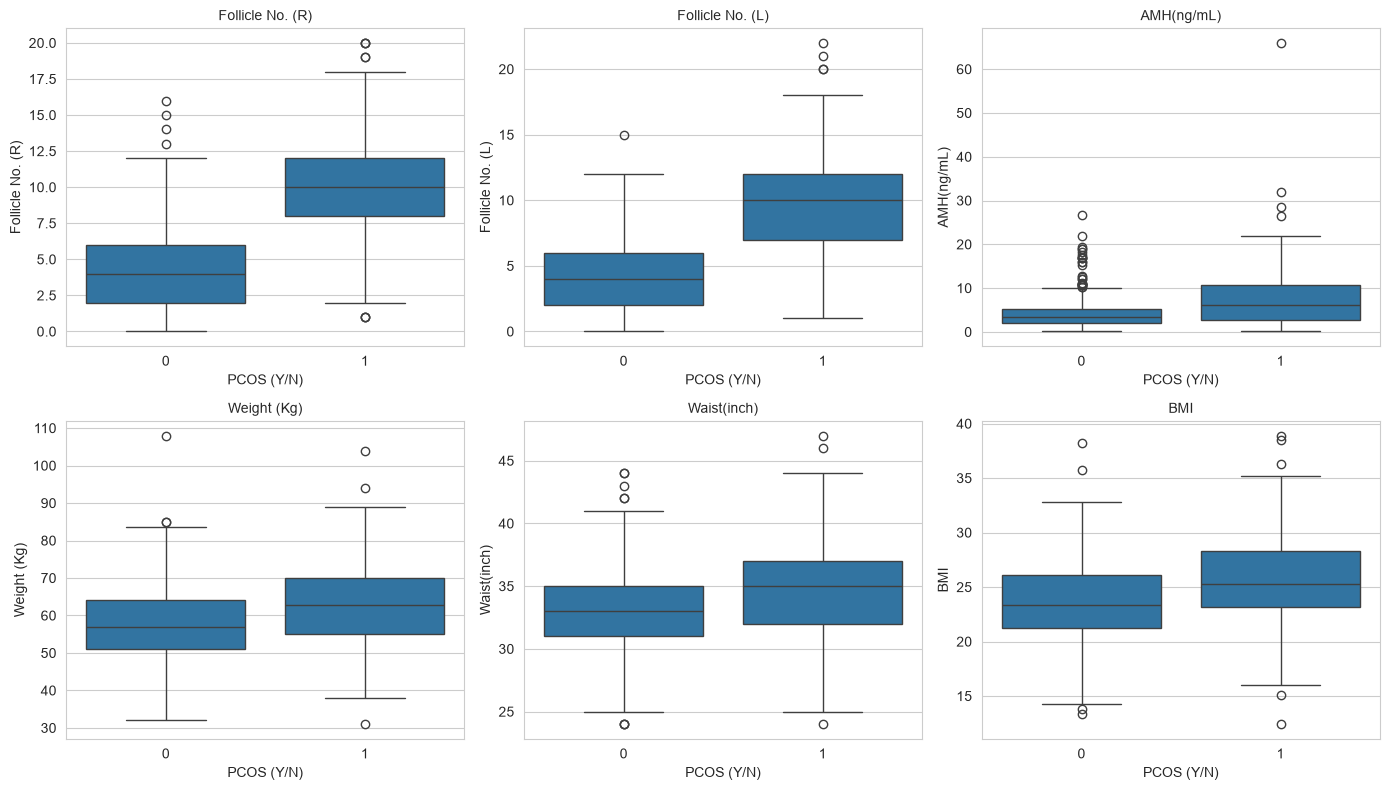

In [10]:
top_num = num_vs_target.head(6)['feature'].tolist()
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, c in zip(axes.flatten(), top_num):
    sns.boxplot(x=df_stat[TARGET], y=df_stat[c], ax=ax); ax.set_title(c, fontsize=10)
plt.tight_layout(); save_fig('fig_boxplots_top6_numeric'); plt.show()


In [11]:
rows = []
for c in categorical_cols:
    t = pd.crosstab(df[c], df[TARGET])
    chi2, p, dof, _ = chi2_contingency(t)
    rows.append([c, chi2, p, np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))])
cat_vs_target = pd.DataFrame(rows, columns=['feature', 'chi2', 'p_value', 'cramers_v'])
cat_vs_target['p_value_BH'] = multipletests(cat_vs_target['p_value'], method='fdr_bh')[1]
cat_vs_target = cat_vs_target.sort_values('cramers_v', ascending=False).reset_index(drop=True)
save_table(cat_vs_target, 'table_categorical_vs_target', index=False)
cat_vs_target.round(4)


,feature,chi2,p_value,cramers_v,p_value_BH
0,Skin darkening (Y/N),96.0510,0.0000,0.4715,0.0000
1,hair growth(Y/N),88.5274,0.0000,0.4527,0.0000
2,Weight gain(Y/N),88.2367,0.0000,0.4519,0.0000
3,Cycle(R/I),59.5709,0.0000,0.3713,0.0000
4,Fast food (Y/N),55.8426,0.0000,0.3595,0.0000
5,Pimples(Y/N),33.7539,0.0000,0.2795,0.0000
6,Hair loss(Y/N),14.5834,0.0001,0.1837,0.0002
7,Blood Group,1.9151,0.9644,0.0666,1.0000
8,Reg.Exercise(Y/N),1.5648,0.2110,0.0602,0.2637
9,Pregnant(Y/N),0.0000,1.0000,0.0000,1.0000


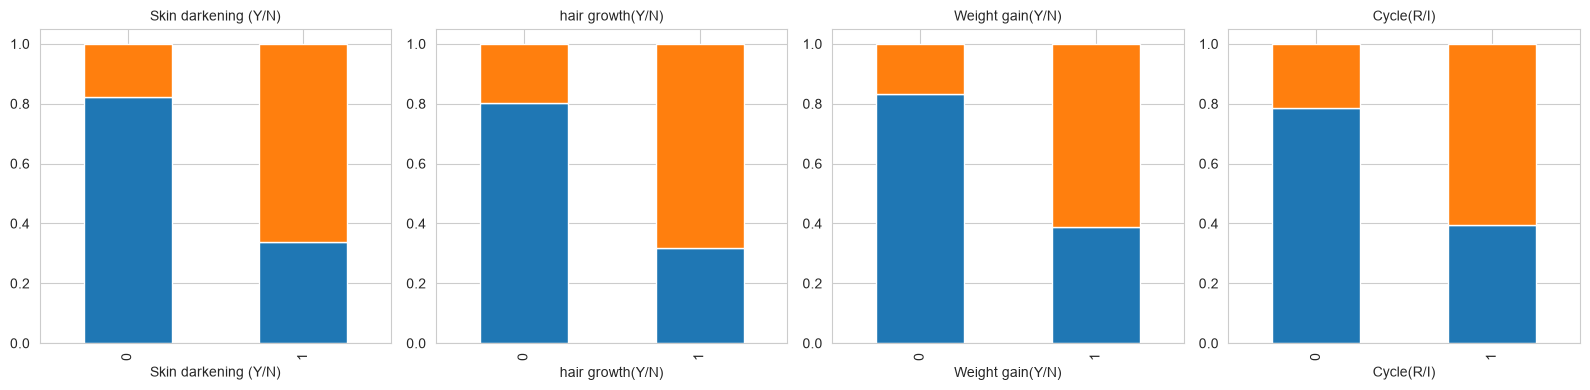

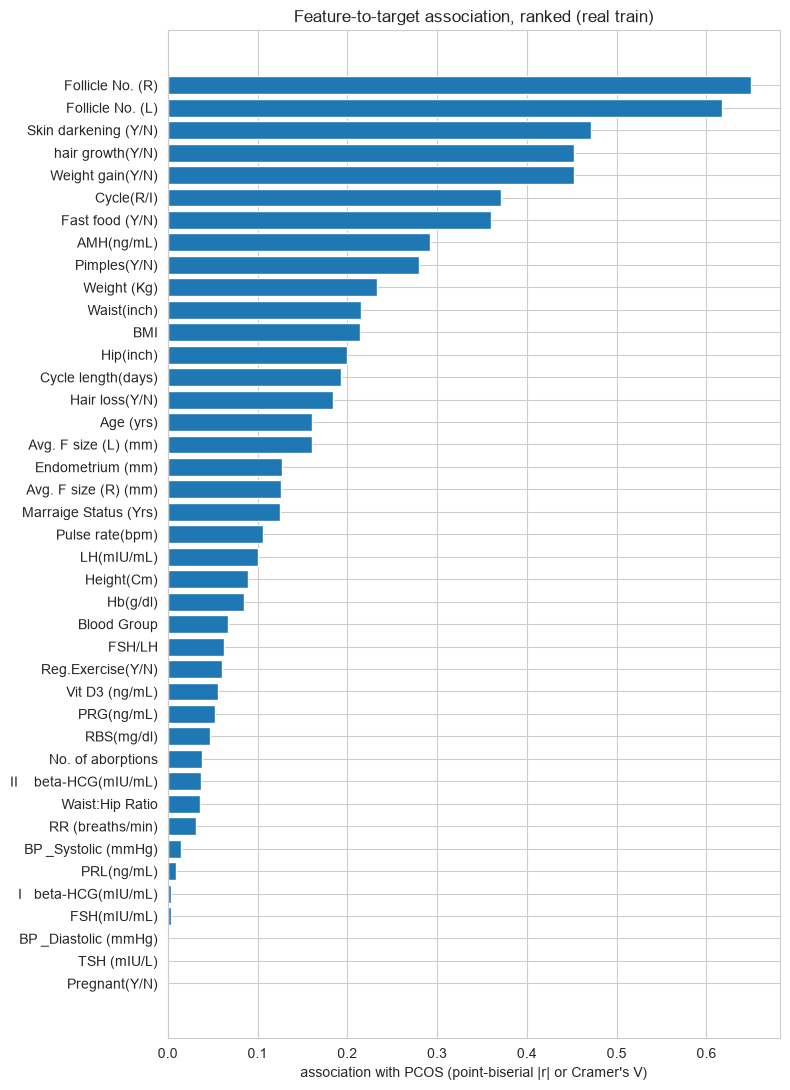

    feature  association
Blood Group        0.067


In [12]:
top_cat = cat_vs_target.head(4)['feature'].tolist()
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, top_cat):
    pd.crosstab(df[c], df[TARGET], normalize='index').plot(kind='bar', stacked=True, ax=ax, legend=False)
    ax.set_title(c, fontsize=10)
plt.tight_layout(); save_fig('fig_stacked_top4_categorical'); plt.show()

combined = pd.concat([num_vs_target[['feature', 'abs_r']].rename(columns={'abs_r': 'association'}),
                      cat_vs_target[['feature', 'cramers_v']].rename(columns={'cramers_v': 'association'})]
                     ).sort_values('association', ascending=False)
plt.figure(figsize=(8, 11))
plt.barh(combined['feature'], combined['association']); plt.gca().invert_yaxis()
plt.xlabel("association with PCOS (point-biserial |r| or Cramer's V)")
plt.title('Feature-to-target association, ranked (real train)')
plt.tight_layout(); save_fig('fig_feature_target_association'); plt.show()
save_table(combined, 'table_feature_target_association', index=False)
print(combined[combined['feature'] == 'Blood Group'].round(3).to_string(index=False))


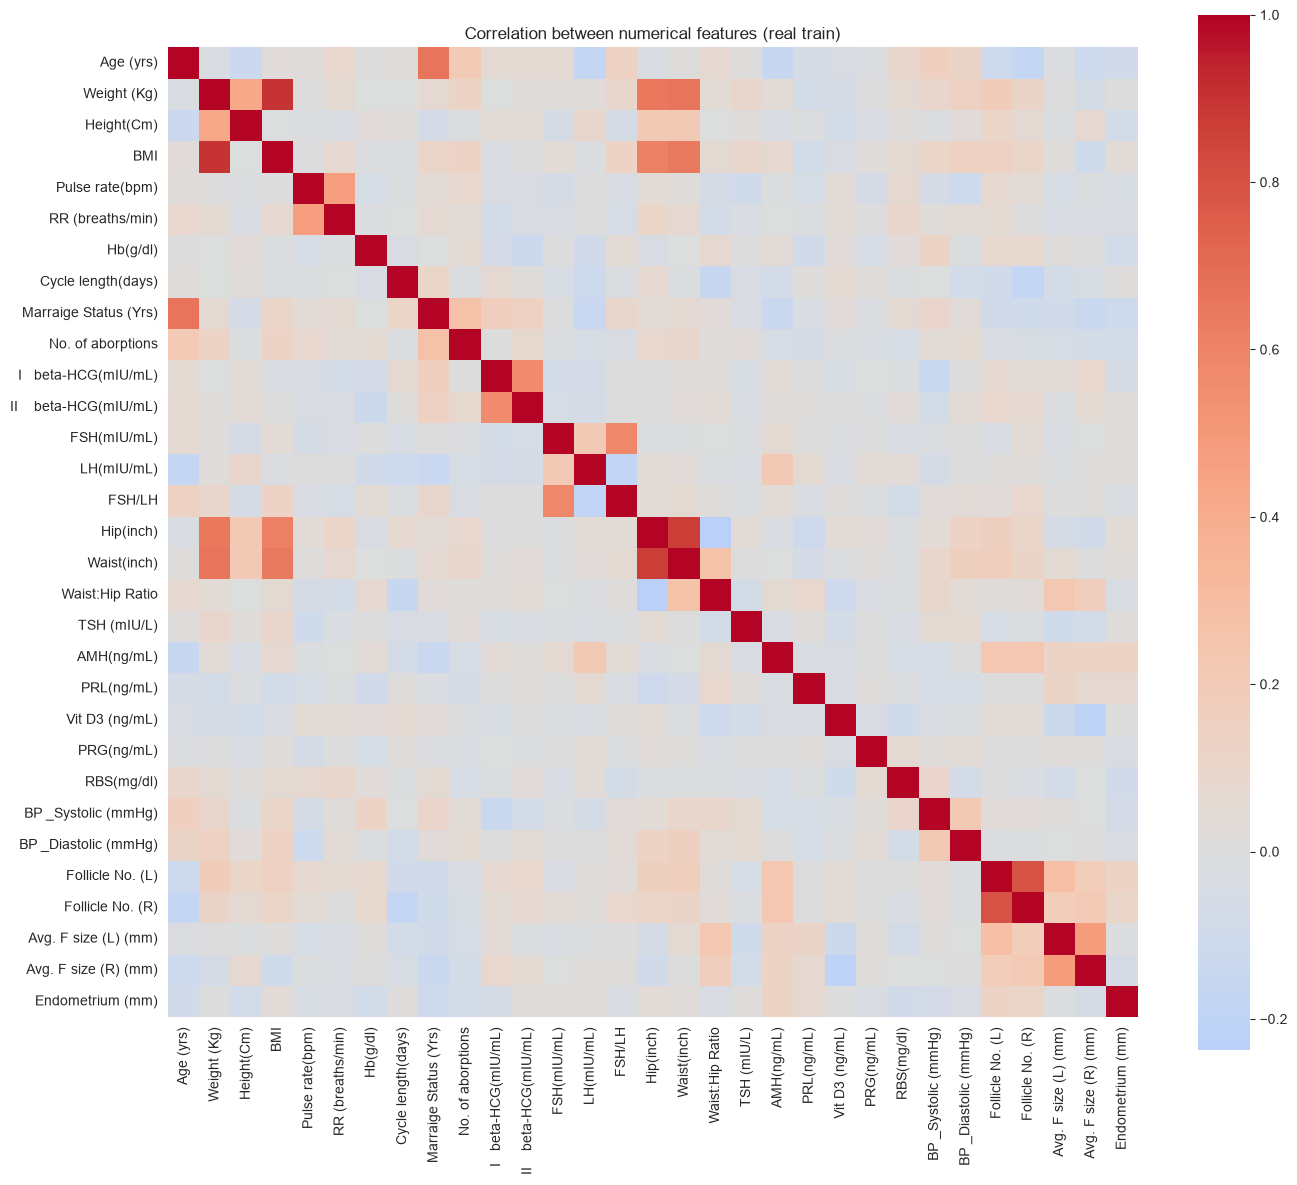

,feature_1,feature_2,r,abs_r
31,Weight (Kg),BMI,0.903,0.903
345,Hip(inch),Waist(inch),0.873,0.873
455,Follicle No. (L),Follicle No. (R),0.797,0.797
7,Age (yrs),Marraige Status (Yrs),0.670,0.670
44,Weight (Kg),Waist(inch),0.669,0.669
43,Weight (Kg),Hip(inch),0.648,0.648
99,BMI,Waist(inch),0.640,0.640
98,BMI,Hip(inch),0.616,0.616
295,FSH(mIU/mL),FSH/LH,0.580,0.580
255,I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),0.564,0.564


In [13]:
corr = df_stat[continuous_cols].corr()
plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap='coolwarm', center=0, square=True)
plt.title('Correlation between numerical features (real train)')
plt.tight_layout(); save_fig('fig_correlation_heatmap'); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().reset_index()
pairs.columns = ['feature_1', 'feature_2', 'r']
pairs['abs_r'] = pairs['r'].abs()
top_pairs = pairs.sort_values('abs_r', ascending=False).head(10)
save_table(top_pairs, 'table_top_correlated_pairs', index=False)
top_pairs.round(3)


In [14]:
# VIF. Derived features (BMI, Waist:Hip, FSH/LH) are built from other columns, so high VIF is expected by design.
Xv = add_constant(df_stat[continuous_cols])
vif = pd.DataFrame({'feature': Xv.columns,
                    'VIF': [variance_inflation_factor(Xv.values, i) for i in range(Xv.shape[1])]})
vif = vif[vif['feature'] != 'const'].sort_values('VIF', ascending=False).reset_index(drop=True)
save_table(vif, 'table_vif', index=False)
vif.round(2).head(12)


,feature,VIF
0,Waist(inch),429.63
1,Hip(inch),421.18
2,Weight (Kg),215.05
3,BMI,178.27
4,Waist:Hip Ratio,108.30
5,Height(Cm),39.96
6,Follicle No. (L),3.20
7,Follicle No. (R),3.09
8,Age (yrs),2.10
9,Marraige Status (Yrs),2.10


## 4. Model training and hold-out test
Selection uses real train only. Test set is touched only for scoring.

In [15]:
X_train, y_train = train_real[cols], train_real[TARGET]
X_test,  y_test  = test_real[cols],  test_real[TARGET]
train_sets = {'Real only': train_real, 'Real + synthetic': aug_train}
for k, v in train_sets.items():
    print(f'{k:18s}', v.shape, 'pos rate %.3f' % v[TARGET].mean())
print('test (all real):  ', X_test.shape, 'pos rate %.3f' % y_test.mean())

def make_pipes(y):
    pos_w = (y == 0).sum() / (y == 1).sum()
    models = {
        'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', C=0.5),
        'Random Forest': RandomForestClassifier(n_estimators=500, min_samples_leaf=2,
                            class_weight='balanced_subsample', random_state=SEED, n_jobs=-1),
        'XGBoost': XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                            colsample_bytree=0.8, scale_pos_weight=pos_w, eval_metric='logloss',
                            random_state=SEED, n_jobs=-1),
        'SVM': SVC(kernel='rbf', C=1.0, class_weight='balanced', probability=True, random_state=SEED),
        'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, learning_rate=0.05,
                            max_depth=3, subsample=0.8, random_state=SEED),
    }
    needs_scaling = ['Logistic Regression', 'SVM']
    pipes = {}
    for name, m in models.items():
        steps = [('imputer', SimpleImputer(strategy='median'))]
        if name in needs_scaling:
            steps.append(('scaler', StandardScaler()))
        steps.append(('model', m))
        pipes[name] = Pipeline(steps)
    return pipes

pipes = make_pipes(y_train)
list(pipes)


Real only          (432, 42) pos rate 0.326
Real + synthetic   (1932, 42) pos rate 0.327
test (all real):   (109, 41) pos rate 0.330


['Logistic Regression', 'Random Forest', 'XGBoost', 'SVM', 'Gradient Boosting']

In [16]:
# 5-fold CV on real train (model comparison)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {'auc': 'roc_auc', 'recall': 'recall', 'precision': 'precision', 'f1': 'f1', 'accuracy': 'accuracy'}
rows = []
for name, p in pipes.items():
    r = cross_validate(p, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({'model': name, **{k: r['test_' + k].mean() for k in scoring}, 'auc_std': r['test_auc'].std()})
cv_table = pd.DataFrame(rows).set_index('model').sort_values('auc', ascending=False)
best_name = cv_table.index[0]
save_table(cv_table.round(4), 'table_cv5_train')
print('Best model by 5-fold CV AUC:', best_name)
cv_table.round(3)


Best model by 5-fold CV AUC: Random Forest


,auc,recall,precision,f1,accuracy,auc_std
model,,,,,,
Random Forest,0.955,0.802,0.902,0.847,0.905,0.019
Gradient Boosting,0.948,0.802,0.866,0.830,0.891,0.022
XGBoost,0.945,0.823,0.818,0.819,0.880,0.021
Logistic Regression,0.936,0.844,0.766,0.803,0.864,0.014
SVM,0.930,0.809,0.759,0.782,0.852,0.016


In [17]:
# fit every model on each training set, score once on the real test set
fitted, probs, rows = {}, {}, []
for set_name, tr in train_sets.items():
    Xtr, ytr = tr[cols], tr[TARGET]
    for name, p in make_pipes(ytr).items():
        p.fit(Xtr, ytr)
        pr = p.predict_proba(X_test)[:, 1]
        pred = (pr >= 0.5).astype(int)
        fitted[(set_name, name)], probs[(set_name, name)] = p, pr
        rows.append({'train set': set_name, 'model': name, 'auc': roc_auc_score(y_test, pr),
                     'pr_auc': average_precision_score(y_test, pr), 'accuracy': accuracy_score(y_test, pred),
                     'recall': recall_score(y_test, pred), 'precision': precision_score(y_test, pred, zero_division=0),
                     'f1': f1_score(y_test, pred)})
test_table = pd.DataFrame(rows).set_index(['train set', 'model'])
save_table(test_table.round(4), 'table_test_real_vs_augmented')
test_table.round(3)


auc  pr_auc  accuracy  recall  \
train set        model                                                  
Real only        Logistic Regression  0.939   0.924     0.872   0.861   
                 Random Forest        0.932   0.929     0.936   0.833   
                 XGBoost              0.950   0.940     0.908   0.833   
                 SVM                  0.936   0.920     0.908   0.833   
                 Gradient Boosting    0.947   0.938     0.917   0.806   
Real + synthetic Logistic Regression  0.946   0.913     0.899   0.944   
                 Random Forest        0.943   0.907     0.881   0.833   
                 XGBoost              0.937   0.910     0.890   0.889   
                 SVM                  0.925   0.881     0.881   0.722   
                 Gradient Boosting    0.941   0.918     0.908   0.861   

                                      precision     f1  
train set        model                                  
Real only        Logistic Regression      0.775  0.816  
                 Random Forest            0.968  0.896  
                 XGBoost                  0.882  0.857  
                 SVM                      0.882  0.857  
                 Gradient Boosting        0.935  0.866  
Real + synthetic Logistic Regression      0.791  0.861  
                 Random Forest            0.811  0.822  
                 XGBoost                  0.800  0.842  
                 SVM                      0.897  0.800  
                 Gradient Boosting        0.861  0.861

In [18]:
# does synthetic data help? paired bootstrap of the AUC gain (aug - real) for the CV-best model
yt = y_test.to_numpy()
rng = np.random.default_rng(SEED)
p_real, p_aug = probs[('Real only', best_name)], probs[('Real + synthetic', best_name)]
diffs = []
for _ in range(2000):
    idx = rng.integers(0, len(yt), len(yt))
    if len(np.unique(yt[idx])) == 2:
        diffs.append(roc_auc_score(yt[idx], p_aug[idx]) - roc_auc_score(yt[idx], p_real[idx]))
syn_gain_lo, syn_gain_hi = np.percentile(diffs, [2.5, 97.5])
print('AUC gain (aug - real) 95%% CI: %.3f to %.3f' % (syn_gain_lo, syn_gain_hi))

chosen_set = 'Real + synthetic' if syn_gain_lo > 0 else 'Real only'
assert chosen_set == 'Real only', 'frozen model is real-only; a change here means going back to Part 2 Step 5'
print('Synthetic gave no proven gain -> train set:', chosen_set)

DEPLOYED = 'Random Forest'                       # model used by the app
probs_chosen = {n: probs[(chosen_set, n)] for n in pipes}
print('CV-best:', best_name, '| deployed:', DEPLOYED)

side = test_table.reset_index().pivot(index='model', columns='train set', values=['auc', 'recall', 'f1'])
side[('auc', 'gain (aug - real)')] = side[('auc', 'Real + synthetic')] - side[('auc', 'Real only')]
side.round(3)


AUC gain (aug - real) 95% CI: -0.018 to 0.045
Synthetic gave no proven gain -> train set: Real only
CV-best: Random Forest | deployed: Random Forest


auc                     recall            \
train set           Real + synthetic Real only Real + synthetic Real only   
model                                                                       
Gradient Boosting              0.941     0.947            0.861     0.806   
Logistic Regression            0.946     0.939            0.944     0.861   
Random Forest                  0.943     0.932            0.833     0.833   
SVM                            0.925     0.936            0.722     0.833   
XGBoost                        0.937     0.950            0.889     0.833   

                                  f1                         auc  
train set           Real + synthetic Real only gain (aug - real)  
model                                                             
Gradient Boosting              0.861     0.866            -0.006  
Logistic Regression            0.861     0.816             0.007  
Random Forest                  0.822     0.896             0.011  
SVM                            0.800     0.857            -0.010  
XGBoost                        0.842     0.857            -0.013

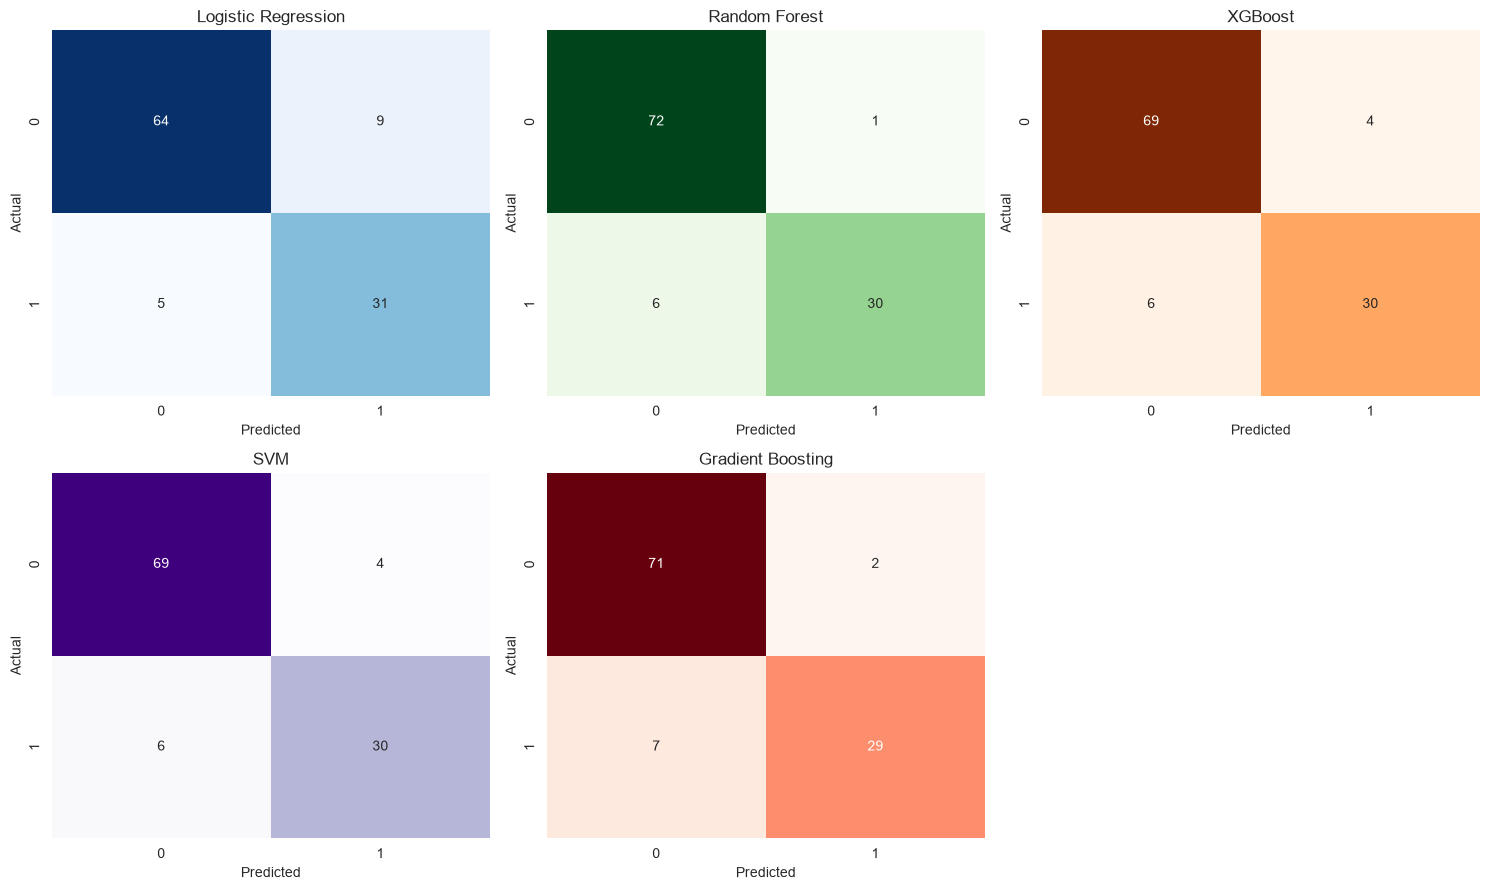

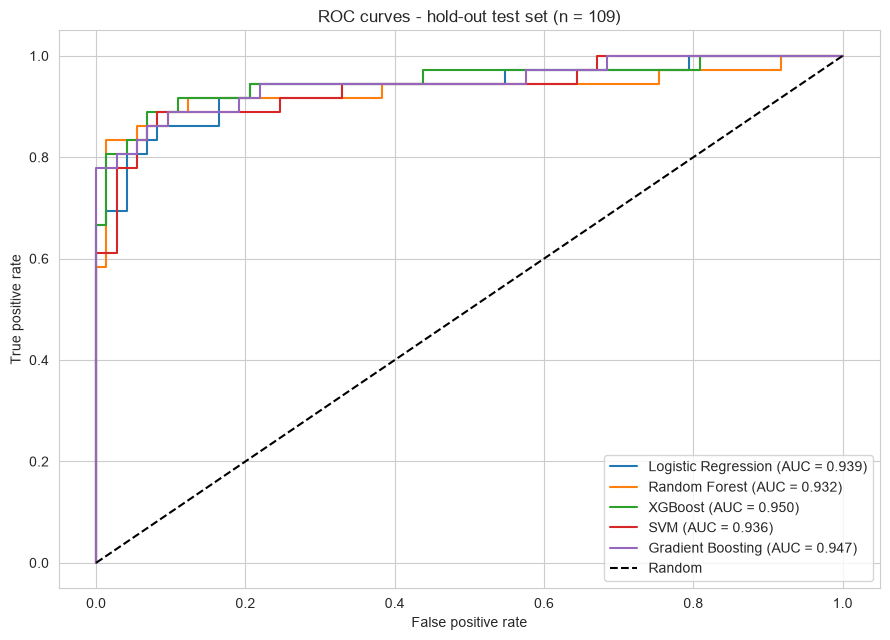

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
cmaps = ['Blues', 'Greens', 'Oranges', 'Purples', 'Reds']
for ax, (name, pr), cm in zip(axes.flatten(), probs_chosen.items(), cmaps):
    sns.heatmap(confusion_matrix(y_test, (pr >= 0.5).astype(int)), annot=True, fmt='d', cmap=cm, ax=ax, cbar=False)
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
axes[1, 2].axis('off')
plt.tight_layout(); save_fig('fig_confusion_matrices'); plt.show()

plt.figure(figsize=(9, 6.5))
for name, pr in probs_chosen.items():
    fpr, tpr, _ = roc_curve(y_test, pr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, pr):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('ROC curves - hold-out test set (n = 109)'); plt.legend(loc='lower right')
plt.tight_layout(); save_fig('fig_roc_curves'); plt.show()


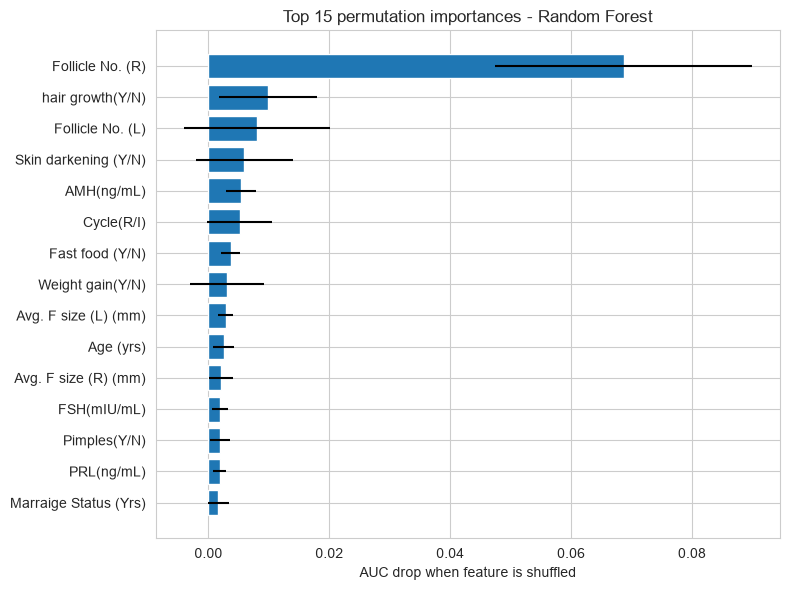

    feature  auc_drop_mean  auc_drop_std  rank
Blood Group        0.00052       0.00041    19


In [20]:
# permutation importance of the DEPLOYED model (descriptive; test set, 30 repeats)
rf_real = fitted[(chosen_set, DEPLOYED)]
perm = permutation_importance(rf_real, X_test, y_test, scoring='roc_auc', n_repeats=30, random_state=SEED, n_jobs=-1)
perm_table = (pd.DataFrame({'feature': cols, 'auc_drop_mean': perm.importances_mean, 'auc_drop_std': perm.importances_std})
              .sort_values('auc_drop_mean', ascending=False).reset_index(drop=True))
perm_table['rank'] = perm_table.index + 1
save_table(perm_table.round(5), 'table_permutation_importance', index=False)

top15 = perm_table.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top15['feature'], top15['auc_drop_mean'], xerr=top15['auc_drop_std'])
plt.title(f'Top 15 permutation importances - {DEPLOYED}')
plt.xlabel('AUC drop when feature is shuffled')
plt.tight_layout(); save_fig('fig_permutation_importance'); plt.show()
print(perm_table[perm_table['feature'] == 'Blood Group'].round(5).to_string(index=False))


## 5. Extra evaluation (2b)
5.1 OOF + bootstrap CI | 5.2 calibration | 5.3 thresholds | 5.4 feature subsets | 5.5 TSTR | 5.6 privacy | 5.7 CV on all 541

### 5.1

In [21]:
# ===== 2b-1: OOF predictions (repeated stratified CV, real train only) + bootstrap CIs on test =====
# Needs from earlier cells: pipes, X_train, y_train, X_test, y_test, probs_chosen, SEED

os.makedirs('results', exist_ok=True)          # notebook runs in data/ -> data/results
N_SPLITS, N_REPEATS, N_BOOT = 5, 5, 2000

# ---- 1) OOF probabilities: one column per repeat, every real-train row predicted once per repeat
rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
yt_tr = y_train.to_numpy()
oof = {n: np.full((N_REPEATS, len(yt_tr)), np.nan) for n in pipes}
for i, (tr_idx, va_idx) in enumerate(rskf.split(X_train, yt_tr)):
    rep = i // N_SPLITS
    for n, p in pipes.items():
        m = clone(p).fit(X_train.iloc[tr_idx], yt_tr[tr_idx])
        oof[n][rep, va_idx] = m.predict_proba(X_train.iloc[va_idx])[:, 1]
for n in oof:
    assert not np.isnan(oof[n]).any(), f'OOF gap in {n}'
oof_mean = {n: oof[n].mean(axis=0) for n in oof}          # average over repeats, used by later cells
np.savez('results/oof_predictions.npz', y=yt_tr, **{n.replace(' ', '_'): v for n, v in oof_mean.items()})

# ---- 2) Bootstrap 95% CI on the 109 test records, all models, threshold 0.5
metrics = {'auc': lambda y, p, pr: roc_auc_score(y, p),
           'recall': lambda y, p, pr: recall_score(y, pr, zero_division=0),
           'precision': lambda y, p, pr: precision_score(y, pr, zero_division=0),
           'f1': lambda y, p, pr: f1_score(y, pr, zero_division=0),
           'accuracy': lambda y, p, pr: accuracy_score(y, pr)}
yt = y_test.to_numpy()
rng = np.random.default_rng(SEED)
idx_all = [rng.integers(0, len(yt), len(yt)) for _ in range(N_BOOT)]
idx_all = [ix for ix in idx_all if len(np.unique(yt[ix])) == 2]    # same resamples for every model

rows = []
for n, p in probs_chosen.items():
    pred = (p >= 0.5).astype(int)
    row = {'model': n}
    for k, f in metrics.items():
        pt = f(yt, p, pred)
        bs = [f(yt[ix], p[ix], pred[ix]) for ix in idx_all]
        lo, hi = np.percentile(bs, [2.5, 97.5])
        row[k] = round(pt, 3); row[k + '_lo'] = round(lo, 3); row[k + '_hi'] = round(hi, 3)
    rows.append(row)

ci_table = pd.DataFrame(rows).set_index('model').sort_values('auc', ascending=False)
ci_table.to_csv('results/table_test_bootstrap_ci.csv')
print('bootstrap resamples used:', len(idx_all), '| test n =', len(yt))
ci_table


bootstrap resamples used: 2000 | test n = 109


,auc,auc_lo,auc_hi,recall,recall_lo,recall_hi,precision,precision_lo,precision_hi,f1,f1_lo,f1_hi,accuracy,accuracy_lo,accuracy_hi
model,,,,,,,,,,,,,,,
XGBoost,0.950,0.889,0.991,0.833,0.703,0.943,0.882,0.767,0.976,0.857,0.761,0.937,0.908,0.853,0.963
Gradient Boosting,0.947,0.889,0.990,0.806,0.667,0.929,0.935,0.840,1.000,0.866,0.769,0.943,0.917,0.862,0.963
Logistic Regression,0.939,0.874,0.984,0.861,0.739,0.968,0.775,0.641,0.897,0.816,0.712,0.902,0.872,0.798,0.927
SVM,0.936,0.875,0.982,0.833,0.703,0.941,0.882,0.760,0.974,0.857,0.762,0.933,0.908,0.853,0.954
Random Forest,0.932,0.857,0.989,0.833,0.703,0.943,0.968,0.895,1.000,0.896,0.807,0.964,0.936,0.890,0.982


### 5.2

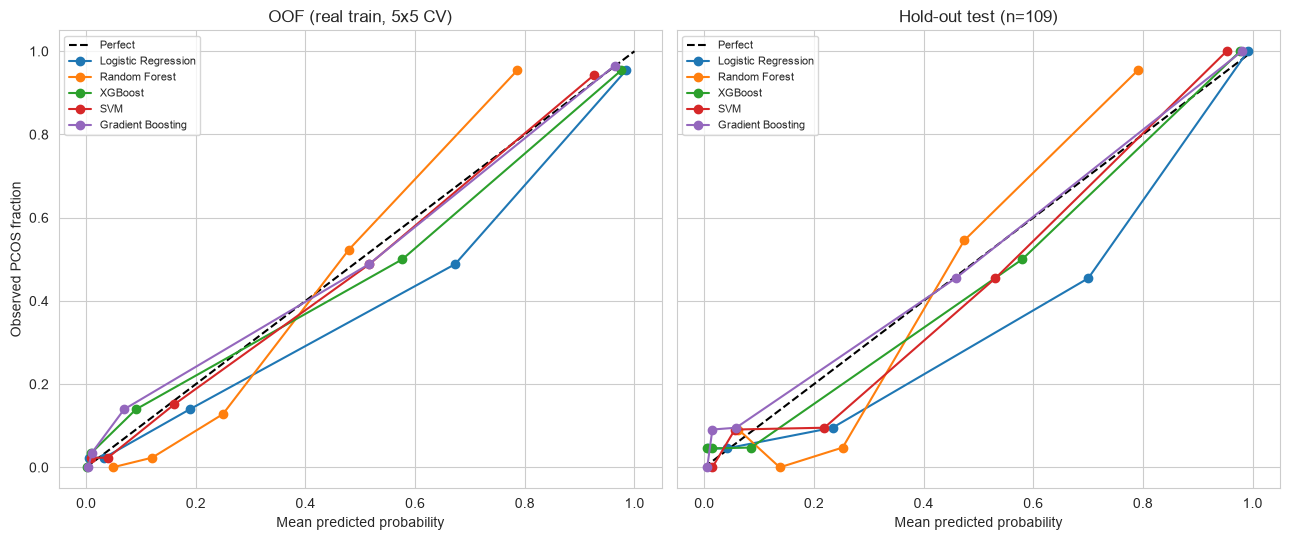

Baseline Brier (prevalence only): OOF 0.2199 | test 0.2212


set,brier_test,brier_oof
model,,
Gradient Boosting,0.0663,0.0782
XGBoost,0.0647,0.0798
SVM,0.0821,0.0894
Random Forest,0.0915,0.0912
Logistic Regression,0.0911,0.0949


In [22]:
# ===== 2b-2: calibration curve + Brier score (OOF on real train, and hold-out test) =====
# Needs: oof_mean, probs_chosen, y_train, y_test, ci_table (from 2b-1)

yt_tr, yt_te = y_train.to_numpy(), y_test.to_numpy()
N_BINS = 5            # small data -> few bins; quantile bins keep each bin populated

rows = []
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, (title, ydata, pdict) in zip(axes, [('OOF (real train, 5x5 CV)', yt_tr, oof_mean),
                                            ('Hold-out test (n=%d)' % len(yt_te), yt_te, probs_chosen)]):
    ax.plot([0, 1], [0, 1], 'k--', label='Perfect')
    for n, p in pdict.items():
        frac, mean_p = calibration_curve(ydata, p, n_bins=N_BINS, strategy='quantile')
        ax.plot(mean_p, frac, marker='o', label=n)
        rows.append({'set': title.split(' (')[0], 'model': n,
                     'brier': round(brier_score_loss(ydata, p), 4)})
    ax.set_title(title); ax.set_xlabel('Mean predicted probability'); ax.legend(fontsize=8)
axes[0].set_ylabel('Observed PCOS fraction')
plt.tight_layout()
plt.savefig('results/fig_calibration.png', dpi=300)
plt.show()

# baseline Brier = always predict prevalence (a useful model must beat it)
base_oof = brier_score_loss(yt_tr, np.full(len(yt_tr), yt_tr.mean()))
base_te = brier_score_loss(yt_te, np.full(len(yt_te), yt_tr.mean()))   # prevalence from train only
brier_table = (pd.DataFrame(rows)
               .pivot(index='model', columns='set', values='brier')
               .rename(columns={'OOF': 'brier_oof', 'Hold-out test': 'brier_test'})
               .sort_values('brier_oof'))
brier_table.to_csv('results/table_brier.csv')
print('Baseline Brier (prevalence only): OOF %.4f | test %.4f' % (base_oof, base_te))
brier_table


### 5.3

In [23]:
# ===== 2b-3: recall-oriented threshold table =====
# Threshold chosen on OOF only. Test scored once with the fixed threshold. No test-set tuning.
# Needs: oof_mean, probs_chosen, y_train, y_test
yt_tr, yt_te = y_train.to_numpy(), y_test.to_numpy()

def conf(y, p, t):
    pred = (p >= t).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    rec = tp / (tp + fn); spec = tn / (tn + fp)
    prec = tp / (tp + fp) if (tp + fp) else float('nan')
    f1 = 2 * prec * rec / (prec + rec) if (tp + fp) and (prec + rec) else float('nan')
    return rec, spec, prec, f1, tp, fn, fp, tn

def pick_threshold(y, p, rule):
    cand = np.unique(np.round(p, 4))
    stats = np.array([conf(y, p, t)[:2] for t in cand])          # recall, specificity
    if rule == 'youden':
        return float(cand[np.argmax(stats[:, 0] + stats[:, 1] - 1)])
    target = float(rule.split('>=')[1])                           # 'recall>=0.90'
    ok = cand[stats[:, 0] >= target]
    return float(ok.max()) if len(ok) else float(cand.min())      # highest t that still hits target

rules = ['youden', 'recall>=0.90', 'recall>=0.95']
rows = []
for n in probs_chosen:
    sel = [(r, pick_threshold(yt_tr, oof_mean[n], r)) for r in rules]
    sel += [('fixed 0.50', 0.50), ('fixed 0.40 (app band)', 0.40)]   # references, not selected
    for rule, t in sel:
        o = conf(yt_tr, oof_mean[n], t)
        te = conf(yt_te, probs_chosen[n], t)
        rows.append({'model': n, 'rule': rule, 'threshold': round(t, 3),
                     'oof_recall': round(o[0], 3), 'oof_spec': round(o[1], 3),
                     'test_recall': round(te[0], 3), 'test_spec': round(te[1], 3),
                     'test_precision': round(te[2], 3), 'test_f1': round(te[3], 3),
                     'TP': te[4], 'FN': te[5], 'FP': te[6], 'TN': te[7]})

thr_table = pd.DataFrame(rows)
thr_table.to_csv('results/table_thresholds.csv', index=False)
thr_table[thr_table['model'] == 'Random Forest']      # deployed model; full table is in the CSV


,model,rule,threshold,oof_recall,oof_spec,test_recall,test_spec,test_precision,test_f1,TP,FN,FP,TN
5,Random Forest,youden,0.457,0.830,0.945,0.833,0.959,0.909,0.870,30,6,3,70
6,Random Forest,recall>=0.90,0.360,0.901,0.852,0.889,0.890,0.800,0.842,32,4,8,65
7,Random Forest,recall>=0.95,0.275,0.950,0.763,0.917,0.740,0.635,0.750,33,3,19,54
8,Random Forest,fixed 0.50,0.500,0.801,0.955,0.833,0.986,0.968,0.896,30,6,1,72
9,Random Forest,fixed 0.40 (app band),0.400,0.858,0.890,0.861,0.904,0.816,0.838,31,5,7,66


### 5.4

In [24]:
# ===== 2b-4: no-ultrasound and few-feature models (paper ablation, app unchanged) =====
# Feature ranking uses real TRAIN only (impurity importance). Test is scored once per subset.
# Needs: pipes, X_train, y_train, X_test, y_test, cols, SEED

ULTRASOUND = ['Follicle No. (L)', 'Follicle No. (R)', 'Avg. F size (L) (mm)',
              'Avg. F size (R) (mm)', 'Endometrium (mm)']
assert set(ULTRASOUND) <= set(cols)

# rank features on train only
rank_rf = clone(pipes['Random Forest']).fit(X_train, y_train)
imp_tr = pd.Series(rank_rf.named_steps['model'].feature_importances_, index=cols).sort_values(ascending=False)
no_us = [c for c in cols if c not in ULTRASOUND]

subsets = {
    f'All features ({len(cols)})': cols,
    f'No ultrasound ({len(no_us)})': no_us,
    'Top 10 (train-ranked)': list(imp_tr.index[:10]),
    'Top 6 (train-ranked)': list(imp_tr.index[:6]),
    'Top 6 without ultrasound': [c for c in imp_tr.index if c not in ULTRASOUND][:6],
}
print('Top 6 train-ranked:', list(imp_tr.index[:6]))
print('Top 6 without ultrasound:', subsets['Top 6 without ultrasound'])

yt = y_test.to_numpy()
rng = np.random.default_rng(SEED)
bidx = [rng.integers(0, len(yt), len(yt)) for _ in range(2000)]
bidx = [ix for ix in bidx if len(np.unique(yt[ix])) == 2]
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

rows = []
for sname, feats in subsets.items():
    for mname in ['Random Forest', 'Logistic Regression']:
        p = clone(pipes[mname])
        oof_p = cross_val_predict(p, X_train[feats], y_train, cv=cv5, method='predict_proba')[:, 1]
        pt = clone(pipes[mname]).fit(X_train[feats], y_train).predict_proba(X_test[feats])[:, 1]
        bs = [roc_auc_score(yt[ix], pt[ix]) for ix in bidx]
        lo, hi = np.percentile(bs, [2.5, 97.5])
        rows.append({'subset': sname, 'n_features': len(feats), 'model': mname,
                     'oof_auc': round(roc_auc_score(y_train, oof_p), 3),
                     'test_auc': round(roc_auc_score(yt, pt), 3),
                     'test_auc_lo': round(lo, 3), 'test_auc_hi': round(hi, 3)})

subset_table = pd.DataFrame(rows)
subset_table.to_csv('results/table_feature_subsets.csv', index=False)
subset_table


Top 6 train-ranked: ['Follicle No. (R)', 'Follicle No. (L)', 'Skin darkening (Y/N)', 'hair growth(Y/N)', 'Weight gain(Y/N)', 'AMH(ng/mL)']
Top 6 without ultrasound: ['Skin darkening (Y/N)', 'hair growth(Y/N)', 'Weight gain(Y/N)', 'AMH(ng/mL)', 'Cycle(R/I)', 'Fast food (Y/N)']


,subset,n_features,model,oof_auc,test_auc,test_auc_lo,test_auc_hi
0,All features (41),41,Random Forest,0.954,0.932,0.857,0.989
1,All features (41),41,Logistic Regression,0.933,0.939,0.874,0.984
2,No ultrasound (36),36,Random Forest,0.882,0.882,0.805,0.947
3,No ultrasound (36),36,Logistic Regression,0.846,0.865,0.784,0.932
4,Top 10 (train-ranked),10,Random Forest,0.953,0.936,0.874,0.984
5,Top 10 (train-ranked),10,Logistic Regression,0.949,0.947,0.881,0.992
6,Top 6 (train-ranked),6,Random Forest,0.943,0.940,0.884,0.984
7,Top 6 (train-ranked),6,Logistic Regression,0.946,0.943,0.878,0.990
8,Top 6 without ultrasound,6,Random Forest,0.840,0.884,0.813,0.942
9,Top 6 without ultrasound,6,Logistic Regression,0.872,0.896,0.828,0.953


### 5.5

In [25]:
# ===== 2b-5: TSTR (train on synthetic only, test on real hold-out) vs TRTR =====
# Reads saved CSV only. No TVAE re-run. Needs: clean, make_pipes, X_test, y_test, cols, probs_chosen, SEED, TARGET
syn = pd.read_csv('run_final/synthetic_pcos.csv')
syn.columns = syn.columns.str.strip()
assert set(syn.columns) == set(cols) | {TARGET}, 'column mismatch'
syn = clean(syn)                                   # same cleaning as real data

# leak guard: no synthetic row equals a test row
key = lambda d: set(d[cols + [TARGET]].round(4).fillna(-999).astype(str).agg('|'.join, axis=1))
assert not (key(syn) & key(test_real)), 'synthetic row copies a test row'

Xs, ys = syn[cols], syn[TARGET]
yt = y_test.to_numpy()
rng = np.random.default_rng(SEED)
bidx = [rng.integers(0, len(yt), len(yt)) for _ in range(2000)]
bidx = [ix for ix in bidx if len(np.unique(yt[ix])) == 2]

rows = []
for n, p in make_pipes(ys).items():
    p.fit(Xs, ys)
    pr = p.predict_proba(X_test)[:, 1]
    auc_s = roc_auc_score(yt, pr)
    auc_r = roc_auc_score(yt, probs_chosen[n])      # TRTR: real-train model, already scored
    lo, hi = np.percentile([roc_auc_score(yt[ix], pr[ix]) for ix in bidx], [2.5, 97.5])
    d = np.percentile([roc_auc_score(yt[ix], pr[ix]) - roc_auc_score(yt[ix], probs_chosen[n][ix])
                       for ix in bidx], [2.5, 97.5])
    pred = (pr >= 0.5).astype(int)
    rows.append({'model': n, 'TRTR_auc': round(auc_r, 3),
                 'TSTR_auc': round(auc_s, 3), 'TSTR_lo': round(lo, 3), 'TSTR_hi': round(hi, 3),
                 'diff_lo': round(d[0], 3), 'diff_hi': round(d[1], 3),
                 'TSTR_recall': round(recall_score(yt, pred), 3),
                 'TSTR_precision': round(precision_score(yt, pred, zero_division=0), 3)})

tstr_table = pd.DataFrame(rows).set_index('model').sort_values('TSTR_auc', ascending=False)
tstr_table.to_csv('results/table_tstr.csv')
print('synthetic rows:', len(syn), '| pos rate %.3f' % ys.mean())
tstr_table


synthetic rows: 1500 | pos rate 0.327


,TRTR_auc,TSTR_auc,TSTR_lo,TSTR_hi,diff_lo,diff_hi,TSTR_recall,TSTR_precision
model,,,,,,,,
Random Forest,0.932,0.937,0.886,0.976,-0.040,0.056,0.917,0.702
XGBoost,0.950,0.915,0.846,0.970,-0.080,0.003,0.889,0.640
Gradient Boosting,0.947,0.901,0.833,0.957,-0.101,0.002,0.889,0.640
Logistic Regression,0.939,0.871,0.797,0.937,-0.137,0.008,0.861,0.620
SVM,0.936,0.802,0.703,0.889,-0.217,-0.052,0.528,0.704


### 5.6

In [26]:
# ===== 2b-6: synthetic privacy check beyond distance. Reads saved CSVs only. No retraining. =====
# Needs: clean, train_real, test_real, cols, SEED

syn_p = pd.read_csv('run_final/synthetic_pcos.csv'); syn_p.columns = syn_p.columns.str.strip()
syn_p = clean(syn_p)

# standardise on real train only; median-impute with train medians
imp = SimpleImputer(strategy='median').fit(train_real[cols])
sc = StandardScaler().fit(imp.transform(train_real[cols]))
T = lambda d: sc.transform(imp.transform(d[cols]))
Z_tr, Z_te, Z_sy = T(train_real), T(test_real), T(syn_p)

nn_tr = NearestNeighbors(n_neighbors=2).fit(Z_tr)
nn_sy = NearestNeighbors(n_neighbors=1).fit(Z_sy)

# 1) exact copies of real train rows
key = lambda d: set(d[cols + [TARGET]].round(4).fillna(-999).astype(str).agg('|'.join, axis=1))
n_exact = len(key(syn_p) & key(train_real))

# 2) DCR: synthetic->train vs real test->train (holdout baseline). Synthetic must NOT be closer than real holdout.
dcr_syn = nn_tr.kneighbors(Z_sy, n_neighbors=1)[0][:, 0]
dcr_te = nn_tr.kneighbors(Z_te, n_neighbors=1)[0][:, 0]
p5_te = np.percentile(dcr_te, 5)
frac_close = float((dcr_syn < p5_te).mean())

# 3) NNDR: nearest / second nearest train neighbour. Near 0 = synthetic row almost copies one train row.
d2 = nn_tr.kneighbors(Z_sy, n_neighbors=2)[0]
nndr = d2[:, 0] / np.maximum(d2[:, 1], 1e-9)

# 4) Membership inference: can distance-to-synthetic tell train rows from test rows? AUC ~0.5 = no leakage.
d_tr = nn_sy.kneighbors(Z_tr)[0][:, 0]
d_te = nn_sy.kneighbors(Z_te)[0][:, 0]
y_mem = np.r_[np.ones(len(d_tr)), np.zeros(len(d_te))]
mia_auc = roc_auc_score(y_mem, -np.r_[d_tr, d_te])
rng = np.random.default_rng(SEED)
bs = []
for _ in range(1000):
    i, j = rng.integers(0, len(d_tr), len(d_tr)), rng.integers(0, len(d_te), len(d_te))
    bs.append(roc_auc_score(np.r_[np.ones(len(i)), np.zeros(len(j))], -np.r_[d_tr[i], d_te[j]]))
mia_lo, mia_hi = np.percentile(bs, [2.5, 97.5])

priv = pd.DataFrame([
    ('exact copies of train rows', n_exact),
    ('DCR synthetic->train: min / median', f'{dcr_syn.min():.3f} / {np.median(dcr_syn):.3f}'),
    ('DCR real test->train: min / median', f'{dcr_te.min():.3f} / {np.median(dcr_te):.3f}'),
    ('share synthetic closer than 5th pct of real holdout', round(frac_close, 4)),
    ('NNDR median / 5th pct', f'{np.median(nndr):.3f} / {np.percentile(nndr, 5):.3f}'),
    ('membership-inference AUC (95% CI)', f'{mia_auc:.3f} ({mia_lo:.3f} to {mia_hi:.3f})'),
], columns=['check', 'value'])
priv.to_csv('results/table_privacy.csv', index=False)
priv


  File "c:\Users\MARUTIRAJ\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\MARUTIRAJ\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\MARUTIRAJ\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\MARUTIRAJ\anaconda3

,check,value
0,exact copies of train rows,0
1,DCR synthetic->train: min / median,2.607 / 4.537
2,DCR real test->train: min / median,2.218 / 5.033
3,share synthetic closer than 5th pct of real ho...,0.116
4,NNDR median / 5th pct,0.957 / 0.823
5,membership-inference AUC (95% CI),0.535 (0.477 to 0.591)


### 5.7

In [27]:
# ===== 2b-7: repeated stratified CV on ALL 541 real records (second performance estimate) =====
# Separate from the train/test split. Imputer and scaler sit inside each pipeline, so they refit per fold.
# Needs: train_real, test_real, cols, make_pipes, SEED, TARGET

real_all = pd.concat([train_real, test_real], ignore_index=True)
assert len(real_all) == 541, len(real_all)
X_all, y_all = real_all[cols], real_all[TARGET].to_numpy()

N_SPLITS, N_REPEATS = 5, 5
rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
base = make_pipes(real_all[TARGET])

oof_all = {n: np.full((N_REPEATS, len(y_all)), np.nan) for n in base}
for i, (tr, va) in enumerate(rskf.split(X_all, y_all)):
    rep = i // N_SPLITS
    for n, p in base.items():
        oof_all[n][rep, va] = clone(p).fit(X_all.iloc[tr], y_all[tr]).predict_proba(X_all.iloc[va])[:, 1]

rng = np.random.default_rng(SEED)
bidx = [rng.integers(0, len(y_all), len(y_all)) for _ in range(1000)]
bidx = [ix for ix in bidx if len(np.unique(y_all[ix])) == 2]

rows = []
for n, M in oof_all.items():
    assert not np.isnan(M).any()
    per_rep = []                                            # one pooled-OOF metric set per repeat
    for r in range(N_REPEATS):
        pr = (M[r] >= 0.5).astype(int)
        per_rep.append([roc_auc_score(y_all, M[r]), recall_score(y_all, pr),
                        precision_score(y_all, pr), f1_score(y_all, pr),
                        accuracy_score(y_all, pr), brier_score_loss(y_all, M[r])])
    m, s = np.mean(per_rep, axis=0), np.std(per_rep, axis=0)
    pm = M.mean(axis=0)                                     # mean over repeats, for bootstrap CI of AUC
    lo, hi = np.percentile([roc_auc_score(y_all[ix], pm[ix]) for ix in bidx], [2.5, 97.5])
    rows.append({'model': n, 'auc': m[0], 'auc_sd_over_repeats': s[0], 'auc_lo': lo, 'auc_hi': hi,
                 'recall': m[1], 'precision': m[2], 'f1': m[3], 'accuracy': m[4], 'brier': m[5]})

cv541_table = pd.DataFrame(rows).set_index('model').sort_values('auc', ascending=False).round(3)
cv541_table.to_csv('results/table_cv_all541.csv')
print(f'{N_SPLITS}x{N_REPEATS} repeated stratified CV, n = {len(y_all)}, positives = {int(y_all.sum())}')
cv541_table


5x5 repeated stratified CV, n = 541, positives = 177


,auc,auc_sd_over_repeats,auc_lo,auc_hi,recall,precision,f1,accuracy,brier
model,,,,,,,,,
Random Forest,0.954,0.003,0.936,0.971,0.798,0.905,0.848,0.906,0.088
XGBoost,0.952,0.004,0.938,0.971,0.832,0.843,0.837,0.894,0.078
Gradient Boosting,0.949,0.004,0.934,0.970,0.808,0.852,0.829,0.891,0.079
SVM,0.936,0.002,0.915,0.958,0.762,0.844,0.800,0.876,0.089
Logistic Regression,0.936,0.003,0.918,0.961,0.844,0.779,0.810,0.871,0.093


## 6. Save the app model
The app reads `../models/`. Trained on real train only, same seed.

In [28]:
os.makedirs('../models', exist_ok=True)
feature_medians = {c: float(X_train[c].median()) for c in cols}      # real train only
assert feature_medians['Cycle(R/I)'] in (0.0, 1.0), 'cycle median wrong'
assert set(train_sets[chosen_set]['Cycle(R/I)'].unique()) <= {0, 1}

with open('../models/feature_medians.json', 'w') as f:
    json.dump(feature_medians, f, indent=2)
with open('../models/feature_schema.pkl', 'wb') as f:
    pickle.dump(cols, f)

tr = train_sets[chosen_set]
final_rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=2, class_weight='balanced_subsample',
                                  random_state=SEED, n_jobs=-1)
final_rf.fit(tr[cols].fillna(feature_medians), tr[TARGET])
with open('../models/rf_pcos_model.pkl', 'wb') as f:
    pickle.dump(final_rf, f)

with open('../models/feature_schema.pkl', 'rb') as f: schema_check = pickle.load(f)
with open('../models/feature_medians.json') as f: medians_check = json.load(f)
with open('../models/rf_pcos_model.pkl', 'rb') as f: model_check = pickle.load(f)
assert schema_check == cols
assert list(medians_check) == cols
assert list(model_check.feature_names_in_) == cols

reloaded_prob = model_check.predict_proba(X_test[schema_check].fillna(medians_check))[:, 1]
saved_rf_auc = roc_auc_score(y_test, reloaded_prob)
print('saved in :', os.path.abspath('../models'))
print('trained on:', chosen_set, tr.shape, '| features:', len(schema_check))
print('reloaded RF test AUC: %.3f' % saved_rf_auc)
assert abs(saved_rf_auc - roc_auc_score(y_test, probs_chosen[DEPLOYED])) < 1e-9, 'saved model differs from evaluated model'


saved in : c:\Users\MARUTIRAJ\Desktop\CycleTwin_AI-2\models
trained on: Real only (432, 42) | features: 41
reloaded RF test AUC: 0.932


## 7. SHAP (optional, needs `pip install shap`)

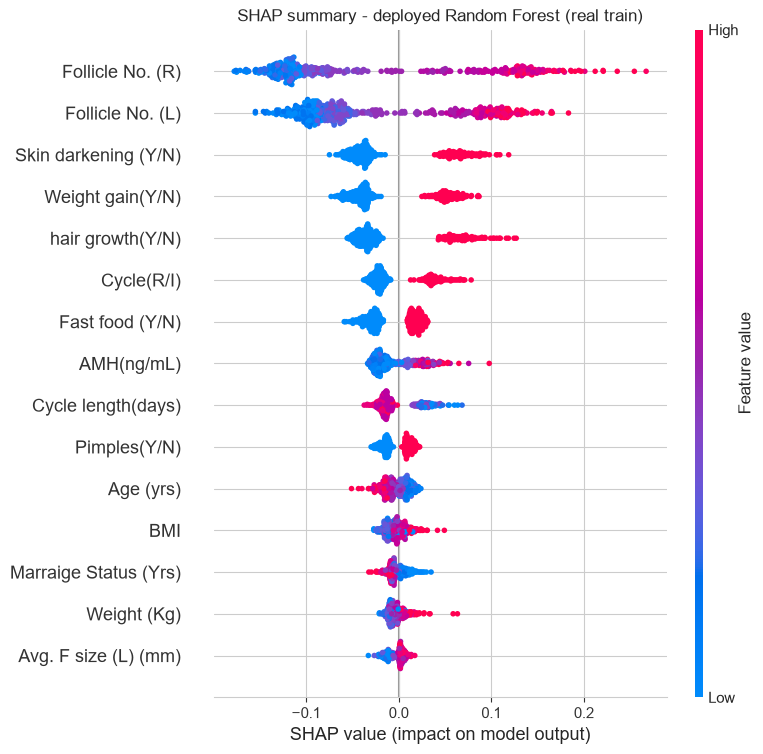

In [29]:
try:
    import shap
    Xs = X_train[cols].fillna(pd.Series(feature_medians))
    sv = shap.TreeExplainer(final_rf).shap_values(Xs)
    sv1 = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if np.ndim(sv) == 3 else sv)
    shap.summary_plot(sv1, Xs, show=False, max_display=15)
    plt.title('SHAP summary - deployed Random Forest (real train)')
    save_fig('fig_shap_summary'); plt.show()
except ImportError:
    print('shap not installed - skipping (optional). Install with: pip install shap')


## 8. Export for the paper

In [30]:
def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

rd_csv = lambda n: pd.read_csv(f'{RESULTS}/{n}.csv')
rf_thr = rd_csv('table_thresholds'); rf_thr = rf_thr[rf_thr['model'] == DEPLOYED]
bg = perm_table[perm_table['feature'] == 'Blood Group'].iloc[0]

summary = {
    'seed': SEED,
    'data': {'n_total': int(len(real_all)), 'n_train': int(len(train_real)), 'n_test': int(len(test_real)),
             'n_features': len(cols), 'n_positive_total': int(real_all[TARGET].sum()),
             'train_pos_rate': round(float(y_train.mean()), 4), 'test_pos_rate': round(float(y_test.mean()), 4),
             'source': 'Kottarathil, P. Polycystic Ovary Syndrome (PCOS), Kaggle; 541 women, 10 hospitals, Kerala, India'},
    'blood_group_codes': {'11': 'A+', '12': 'A-', '13': 'B+', '14': 'B-', '15': 'O+', '16': 'O-', '17': 'AB+', '18': 'AB-'},
    'model_selection': {'cv5_best_by_auc': best_name, 'deployed_model': DEPLOYED, 'train_set': chosen_set,
                        'synthetic_auc_gain_ci95': [round(float(syn_gain_lo), 4), round(float(syn_gain_hi), 4)],
                        'saved_model_test_auc': round(float(saved_rf_auc), 4)},
    'app_bands': {'label_threshold': 0.5, 'bands': [0.40, 0.70], 'status': 'heuristic, uncalibrated'},
    'blood_group_permutation_importance': {'rank': int(bg['rank']), 'of': len(cols),
                                           'auc_drop_mean': round(float(bg['auc_drop_mean']), 5)},
    'top10_permutation_importance': perm_table.head(10)[['feature', 'auc_drop_mean']].round(5).to_dict('records'),
    'tables': {n: rd_csv(n).round(4).to_dict('records') for n in
               ['table_cv5_train', 'table_test_bootstrap_ci', 'table_brier', 'table_feature_subsets',
                'table_tstr', 'table_privacy', 'table_cv_all541']},
    'deployed_model_thresholds': rf_thr.to_dict('records'),
    'versions': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                 'sklearn': sklearn.__version__, 'scipy': scipy.__version__, 'xgboost': xgboost.__version__},
    'sha256': {**{f'run_final/{f}': sha256(f'run_final/{f}') for f in
                  ['train_real.csv', 'test_real.csv', 'synthetic_pcos.csv', 'augmented_train.csv']},
               **{f'models/{f}': sha256(f'../models/{f}') for f in
                  ['rf_pcos_model.pkl', 'feature_schema.pkl', 'feature_medians.json']}},
}
with open(f'{RESULTS}/results_summary.json', 'w') as f:
    json.dump(summary, f, indent=2, default=str)

expected = ['table1_descriptive.csv', 'table_cv5_train.csv', 'table_test_real_vs_augmented.csv',
            'table_test_bootstrap_ci.csv', 'table_brier.csv', 'table_thresholds.csv', 'table_feature_subsets.csv',
            'table_tstr.csv', 'table_privacy.csv', 'table_cv_all541.csv', 'table_permutation_importance.csv',
            'fig_class_distribution.png', 'fig_roc_curves.png', 'fig_confusion_matrices.png',
            'fig_calibration.png', 'fig_permutation_importance.png', 'fig_feature_target_association.png',
            'results_summary.json']
missing = [e for e in expected if not os.path.exists(f'{RESULTS}/{e}')]
assert not missing, f'missing outputs: {missing}'
print('exported', len(os.listdir(RESULTS)), 'files to', os.path.abspath(RESULTS))


exported 30 files to c:\Users\MARUTIRAJ\Desktop\CycleTwin_AI-2\data\results
